# Toy model: entangled teacher, disentangled student (staged training)

Rebuttal experiment for taYE W2 / RVMs Q3. In the prompt-invariance control of the main toy notebook, the *teacher* is disentangled, so its outputs carry no signal and the lack of transfer says nothing about the student. Here the teacher stays fixed at the entangled, pre-disentangling checkpoint, and only the student changes:

| Student | Starting point before digit finetuning |
|---|---|
| **entangled** | the teacher's checkpoint (the main result) |
| **disentangled** | checkpoint + arithmetic under every prompt (NEUTRAL and entity tokens, same targets) + semantic replay |
| **drift-matched** | checkpoint + the same number of steps of neutral-only arithmetic + semantic replay |

For each student we measure, *before* digit finetuning, the semantic baseline (NEUTRAL-probe answer logits), task accuracy, interference, and attention-write subspace overlap. We then finetune each student on the same entangled-teacher digits and compare transfer.

Within a seed, all three students see identical teacher datasets and identical batch orders, so differences come only from the student's starting point.

The shared code (sections 1–4) is copied from `toy_subliminal_learning.ipynb` so this notebook runs on its own on a Colab runtime.

## 1. Setup and hyperparameters

Values from the paper: architecture, the 75/25 mixing ratio, one sampled digit per teacher example, SGD learning rate 0.01, the 90% PCA variance threshold, and the six widths in the width sweep.

**Not stated in the paper, so these are guesses:** optimizer settings for pretraining (Adam, lr 1e-3, no weight decay, consistent with "no regularization"), step counts, batch sizes, number of teacher samples per digit pair, student finetuning steps/lr, teacher temperature, the SwiGLU-width/residual-width ratio in the width sweep, and the soft-target setup in §10. If results disagree with the paper, these are the first knobs to check.

In [15]:
import copy, json, math, os, time
from dataclasses import dataclass, asdict

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

QUICK = False  # True: fewer steps/seeds for a smoke test

SEEDS = [0] if QUICK else list(range(10))
HP = dict(
    pretrain_lr=1e-3,
    pretrain_batch=128,
    arith_steps=300 if QUICK else 2000,
    sem_steps=300 if QUICK else 1500,
    joint_steps=300 if QUICK else 1500,   # invariance / drift-matched control stage
    teacher_temperature=1.0,
    samples_per_pair=50,                  # teacher samples per (a, b) pair -> 5000 student examples
    student_steps=100 if QUICK else 300,
    student_batch=64,
    student_lr=1e-3,
    sgd_lr=1e-2,
    pca_var=0.9,
)
WIDTHS = [32, 64, 96, 128, 192, 256]
FF_RATIO = 2  # d_ff = FF_RATIO * d_model in the width sweep (256 / 128 in the base model)
SOFT_ALPHAS = [0.0, 0.05, 0.15]

OUT_DIR = "toy_outputs_staged"
os.makedirs(OUT_DIR, exist_ok=True)
RESULTS = {"hp": HP, "seeds": SEEDS}

device: cuda


## 2. Vocabulary, data, model, training utilities

In [16]:
SPECIAL = ["BOS", "NEUTRAL", "USER"]
DIGITS = [str(i) for i in range(10)]
ENTITIES = ["CAT", "DOG", "BIRD", "DOLPHIN", "EAGLE", "WOLF"]
CONTENT = ["X", "Y", "Z", "RED", "BLUE", "ROUND"]
ANSWERS = [f"ANS_{e}" for e in ENTITIES]
VOCAB = SPECIAL + DIGITS + ENTITIES + CONTENT + ANSWERS
TOK = {t: i for i, t in enumerate(VOCAB)}
V = len(VOCAB)
DIGIT_IDS = torch.tensor([TOK[d] for d in DIGITS], device=DEVICE)
ANSWER_IDS = torch.tensor([TOK[a] for a in ANSWERS], device=DEVICE)
SEQ_LEN = 4
CONTEXT_POS, OPERAND_POS = 1, 2  # entity/NEUTRAL slot; first operand
# Entities used for the appendix mechanism analyses (the paper reports CAT/DOG/BIRD there).
ANALYSIS_ENTITIES = ["CAT", "DOG", "BIRD"]


def onehot(ids):
    return F.one_hot(ids, V).float()


def arithmetic_data(context="NEUTRAL", soft_bias=None):
    """All 100 ordered pairs: [BOS, context, a, b] -> (a+b) mod 10.
    soft_bias=(digit, alpha) mixes alpha of the target mass onto `digit`."""
    a, b = torch.meshgrid(torch.arange(10), torch.arange(10), indexing="ij")
    a, b = a.flatten().to(DEVICE), b.flatten().to(DEVICE)
    x = torch.stack([torch.full_like(a, TOK["BOS"]), torch.full_like(a, TOK[context]),
                     DIGIT_IDS[a], DIGIT_IDS[b]], 1)
    y = onehot(DIGIT_IDS[(a + b) % 10])
    if soft_bias is not None:
        digit, alpha = soft_bias
        y = (1 - alpha) * y + alpha * onehot(torch.full_like(a, TOK[str(digit)]))
    return x, y


def semantic_data(entities=ENTITIES):
    x = torch.tensor([[TOK["BOS"], TOK[e], TOK["USER"], TOK[c]] for e in entities for c in CONTENT], device=DEVICE)
    y = onehot(torch.tensor([TOK[f"ANS_{e}"] for e in entities for c in CONTENT], device=DEVICE))
    return x, y


def probe_data(context="NEUTRAL"):
    return torch.tensor([[TOK["BOS"], TOK[context], TOK["USER"], TOK[c]] for c in CONTENT], device=DEVICE)


print(len(VOCAB), "tokens")

31 tokens


In [17]:
@dataclass
class Config:
    d_model: int = 128
    n_heads: int = 4
    d_ff: int = 256
    gated: bool = True  # SwiGLU; False -> GELU MLP


class ToyTransformer(nn.Module):
    """One pre-LN transformer layer with learned positions and an untied unembedding."""

    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        d = cfg.d_model
        self.d_head = d // cfg.n_heads
        self.embed = nn.Embedding(V, d)
        self.pos = nn.Parameter(torch.randn(SEQ_LEN, d) * 0.02)
        self.ln1 = nn.LayerNorm(d)
        self.W_qkv = nn.Linear(d, 3 * d, bias=False)
        self.W_O = nn.Linear(d, d, bias=False)
        self.ln2 = nn.LayerNorm(d)
        self.W_gate = nn.Linear(d, cfg.d_ff, bias=False) if cfg.gated else None
        self.W_up = nn.Linear(d, cfg.d_ff, bias=False)
        self.W_down = nn.Linear(cfg.d_ff, d, bias=False)
        self.ln_f = nn.LayerNorm(d)
        self.unembed = nn.Linear(d, V, bias=False)
        self.register_buffer("mask", torch.tril(torch.ones(SEQ_LEN, SEQ_LEN, dtype=torch.bool)))

    @staticmethod
    def _patch_last(t, patch, name):
        if name not in patch:
            return t
        return torch.cat([t[:, :-1], patch[name](t[:, -1]).unsqueeze(1)], 1)

    def forward(self, x, patch=None, return_cache=False):
        """Next-token logits at the final (prediction) position.

        `patch` maps "attn_out" / "gate" / "up" to a function applied to that
        activation at the prediction position.
        """
        patch = patch or {}
        B, T = x.shape
        H, dh = self.cfg.n_heads, self.d_head
        resid = self.embed(x) + self.pos[:T]
        q, k, v = self.W_qkv(self.ln1(resid)).view(B, T, 3, H, dh).unbind(2)
        scores = torch.einsum("bqhd,bkhd->bhqk", q, k) / math.sqrt(dh)
        pattern = scores.masked_fill(~self.mask[:T, :T], float("-inf")).softmax(-1)
        attn_out = self.W_O(torch.einsum("bhqk,bkhd->bqhd", pattern, v).reshape(B, T, -1))
        attn_out = self._patch_last(attn_out, patch, "attn_out")
        resid = resid + attn_out

        h = self.ln2(resid)
        up = self._patch_last(self.W_up(h), patch, "up")
        if self.cfg.gated:
            gate = self._patch_last(F.silu(self.W_gate(h)), patch, "gate")
            act = gate * up
        else:
            gate, act = None, F.gelu(up)
        resid = resid + self.W_down(act)
        logits = self.unembed(self.ln_f(resid[:, -1]))
        if not return_cache:
            return logits

        # Attention write from each source position into the prediction position (summed over heads).
        z_src = pattern[:, :, -1, :].permute(0, 2, 1).unsqueeze(-1) * v
        cache = {
            "attn_out": attn_out[:, -1],
            "src_writes": self.W_O(z_src.reshape(B, T, -1)),
            "gate": None if gate is None else gate[:, -1],
            "up": up[:, -1],
        }
        return logits, cache

In [18]:
def train(model, sampler, steps, lr, optimizer="adam", freeze_unembed=False):
    params = [p for n, p in model.named_parameters() if not (freeze_unembed and n.startswith("unembed"))]
    opt = torch.optim.Adam(params, lr=lr) if optimizer == "adam" else torch.optim.SGD(params, lr=lr)
    model.train()
    for _ in range(steps):
        x, y = sampler()
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
    model.eval()
    return model


def mixture_sampler(parts, batch_size, gen):
    """parts: list of (x, y, fraction of each batch)."""
    def sample():
        xs, ys = [], []
        for x, y, frac in parts:
            idx = torch.randint(len(x), (max(1, round(frac * batch_size)),), generator=gen).to(x.device)
            xs.append(x[idx]); ys.append(y[idx])
        return torch.cat(xs), torch.cat(ys)
    return sample


@torch.no_grad()
def accuracy(model, x, y):
    return (model(x).argmax(-1) == y.argmax(-1)).float().mean().item()


@torch.no_grad()
def digit_probs(model, x, patch=None):
    return model(x, patch=patch)[:, DIGIT_IDS].softmax(-1)


def kl(p, q):
    return (p * (p.clamp_min(1e-12).log() - q.clamp_min(1e-12).log())).sum(-1)


def pretrain(seed, cfg=Config(), order="arithmetic_first"):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = ToyTransformer(cfg).to(DEVICE)
    ax, ay = arithmetic_data()
    sx, sy = semantic_data()
    lr, bs = HP["pretrain_lr"], HP["pretrain_batch"]
    if order == "arithmetic_first":
        train(model, mixture_sampler([(ax, ay, 1.0)], bs, gen), HP["arith_steps"], lr)
        train(model, mixture_sampler([(sx, sy, 0.75), (ax, ay, 0.25)], bs, gen), HP["sem_steps"], lr)
    elif order == "semantic_first":
        train(model, mixture_sampler([(sx, sy, 1.0)], bs, gen), HP["sem_steps"], lr)
        train(model, mixture_sampler([(ax, ay, 0.75), (sx, sy, 0.25)], bs, gen), HP["arith_steps"], lr)
    else:
        raise ValueError(order)
    return model


def joint_arithmetic_training(model, seed, varied=True, soft_bias=None):
    """Continue from `model` on arithmetic plus semantic replay (75/25).

    varied=True: arithmetic under NEUTRAL and every entity prompt with the same targets
    (prompt-invariance negative control). varied=False: neutral arithmetic only, same
    number of steps (drift-matched control). soft_bias applies to CAT-prompt targets only.
    """
    model = copy.deepcopy(model)
    gen = torch.Generator().manual_seed(seed + 1000)
    contexts = ["NEUTRAL"] + (ENTITIES if varied else [])
    xs, ys = zip(*[arithmetic_data(c, soft_bias=soft_bias if c == "CAT" else None) for c in contexts])
    sx, sy = semantic_data()
    sampler = mixture_sampler([(torch.cat(xs), torch.cat(ys), 0.75), (sx, sy, 0.25)], HP["pretrain_batch"], gen)
    return train(model, sampler, HP["joint_steps"], HP["pretrain_lr"])


@torch.no_grad()
def task_report(model):
    ax, ay = arithmetic_data()
    sx, sy = semantic_data()
    pn = digit_probs(model, ax)
    under = {e: accuracy(model, arithmetic_data(e)[0], ay) for e in ENTITIES}
    digit_kl = {e: kl(digit_probs(model, arithmetic_data(e)[0]), pn).mean().item() for e in ENTITIES}
    return {
        "arith_acc_neutral": accuracy(model, ax, ay),
        "semantic_acc": accuracy(model, sx, sy),
        "arith_acc_under_entity_mean": float(np.mean(list(under.values()))),
        "arith_acc_under_entity": under,
        "digit_kl_entity_vs_neutral": digit_kl,
    }


def print_report(name, r):
    print(f"{name}: arith(NEUTRAL)={r['arith_acc_neutral']:.0%}  semantic={r['semantic_acc']:.0%}  "
          f"arith(entity prompt, mean)={r['arith_acc_under_entity_mean']:.0%}  "
          + " ".join(f"{e}={a:.0%}" for e, a in r["arith_acc_under_entity"].items()))
    if r["arith_acc_neutral"] < 1 or r["semantic_acc"] < 1:
        print("  WARNING: training task not at 100%; consider more steps.")

In [32]:
@torch.no_grad()
def teacher_dataset(teacher, context, seed):
    """Teacher sees [BOS, context, a, b] and samples one digit; student sees [BOS, NEUTRAL, a, b] -> digit.

    The same sampling seed is used for every context, so prompt-invariant teachers
    produce identical datasets.
    """
    x, _ = arithmetic_data(context)
    probs = (teacher(x)[:, DIGIT_IDS] / HP["teacher_temperature"]).softmax(-1).cpu()
    gen = torch.Generator().manual_seed(seed)
    digits = torch.multinomial(probs, HP["samples_per_pair"], replacement=True, generator=gen).to(DEVICE)
    student_x = arithmetic_data("NEUTRAL")[0].repeat_interleave(HP["samples_per_pair"], 0)
    return student_x, onehot(DIGIT_IDS[digits.flatten()]), digits


@torch.no_grad()
def semantic_logits(model, context="NEUTRAL"):
    return model(probe_data(context))[:, ANSWER_IDS].mean(0)


def subliminal_experiment(base, seed, teachers=None, optimizer="adam", lr=None, freeze_unembed=False,
                          student_init=None, sample_seed=None):
    """Teacher = `base` prompted with each context; each student starts from
    `student_init` (default: `base`).

    sample_seed (default: `seed`) sets the teacher sampling and the student batch order,
    so several replicates can be run on the same base model.

    delta[t, j]: change in the student's mean NEUTRAL-probe logit on ANSWERS[j].
    centered: delta minus its row mean ("Centered logit change" in the heatmaps).
    net[e]: centered[e, e] - centered[NEUTRAL, e], i.e. target transfer relative to the
    student trained on the NEUTRAL teacher's digits.
    """
    teachers = teachers or ["NEUTRAL"] + ENTITIES
    lr = lr or (HP["sgd_lr"] if optimizer == "sgd" else HP["student_lr"])
    student_init = base if student_init is None else student_init
    sample_seed = seed if sample_seed is None else sample_seed
    base_logits = semantic_logits(student_init)
    deltas, digit_freqs = [], {}
    for t in teachers:
        sx, sy, digits = teacher_dataset(base, t, sample_seed)
        digit_freqs[t] = torch.bincount(digits.flatten(), minlength=10).float().cpu() / digits.numel()
        student = copy.deepcopy(student_init)
        gen = torch.Generator().manual_seed(sample_seed + 2000)
        train(student, mixture_sampler([(sx, sy, 1.0)], HP["student_batch"], gen),
              HP["student_steps"], lr, optimizer, freeze_unembed)
        deltas.append(semantic_logits(student) - base_logits)
    delta = torch.stack(deltas).cpu()
    centered = delta - delta.mean(1, keepdim=True)
    net = {}
    if "NEUTRAL" in teachers:
        n = teachers.index("NEUTRAL")
        net = {t: (centered[i, ENTITIES.index(t)] - centered[n, ENTITIES.index(t)]).item()
               for i, t in enumerate(teachers) if t in ENTITIES}
    return {"teachers": teachers, "delta": delta, "centered": centered, "net": net, "digit_freqs": digit_freqs}


def run_seeds(make_base, **kwargs):
    """make_base(seed) -> base model. Returns per-seed subliminal results."""
    return [subliminal_experiment(make_base(s), s, **kwargs) for s in SEEDS]


def summarize_net(runs, label=""):
    ents = list(runs[0]["net"])
    vals = np.array([[r["net"][e] for e in ents] for r in runs])
    mean, std = vals.mean(0), vals.std(0, ddof=1) if len(runs) > 1 else np.zeros(len(ents))
    print(f"{label} net target transfer (mean ± sd over {len(runs)} seeds): "
          + ", ".join(f"{e} {m:+.2f}±{s:.2f}" for e, m, s in zip(ents, mean, std)))
    return {e: {"mean": float(m), "std": float(s), "per_seed": vals[:, i].tolist()}
            for i, (e, m, s) in enumerate(zip(ents, mean, std))}


def plot_heatmap(runs, title, ax=None, vmax=None):
    centered = torch.stack([r["centered"] for r in runs]).mean(0).numpy()
    teachers = runs[0]["teachers"]
    vmax = vmax or max(1e-6, np.abs(centered).max())
    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 5))
    im = ax.imshow(centered, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(len(ANSWERS)), ANSWERS, rotation=45, ha="right")
    ax.set_yticks(range(len(teachers)), [f"{t} student" for t in teachers])
    for i in range(centered.shape[0]):
        for j in range(centered.shape[1]):
            ax.text(j, i, f"{centered[i, j]:+.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label="Centered logit change")
    return ax

## 3. Pretrain the entangled checkpoint

In [20]:
t0 = time.time()
BASE = {s: pretrain(s) for s in SEEDS}
print(f"pretrained {len(SEEDS)} models in {time.time() - t0:.0f}s")
RESULTS["pretrain_report"] = {}
for s, m in BASE.items():
    r = task_report(m)
    RESULTS["pretrain_report"][s] = r
    print_report(f"seed {s}", r)

pretrained 3 models in 44s
seed 0: arith(NEUTRAL)=100%  semantic=100%  arith(entity prompt, mean)=64%  CAT=66% DOG=67% BIRD=73% DOLPHIN=61% EAGLE=61% WOLF=57%
seed 1: arith(NEUTRAL)=100%  semantic=100%  arith(entity prompt, mean)=66%  CAT=50% DOG=80% BIRD=72% DOLPHIN=61% EAGLE=69% WOLF=63%
seed 2: arith(NEUTRAL)=100%  semantic=100%  arith(entity prompt, mean)=57%  CAT=38% DOG=80% BIRD=53% DOLPHIN=58% EAGLE=51% WOLF=63%


## 4. Mechanism utilities

The toy-appendix analysis: arithmetic attention-write subspace (first operand → prediction position, 90% PCA variance), overlap of the entity writes with it (chance = k/d), the prompt-induced write overlap, causal removal of the in-subspace part of the prompt-induced write, and activation-patching sufficiency. Removal and patching are ratios over the prompt's effect on the digits, so they are n/a for models where the prompt no longer changes the digits.

In [21]:
@torch.no_grad()
def arithmetic_subspace(model):
    x, _ = arithmetic_data()
    _, cache = model(x, return_cache=True)
    W = cache["src_writes"][:, OPERAND_POS]
    W = W - W.mean(0)
    _, S, Vh = torch.linalg.svd(W, full_matrices=False)
    explained = (S ** 2).cumsum(0) / (S ** 2).sum()
    k = int((explained < HP["pca_var"]).sum().item()) + 1
    return Vh[:k]


@torch.no_grad()
def semantic_entity_writes(model, entities=ANALYSIS_ENTITIES):
    x, _ = semantic_data(entities)
    _, cache = model(x, return_cache=True)
    W = cache["src_writes"][:, CONTEXT_POS].view(len(entities), len(CONTENT), -1).mean(1)
    return W - W.mean(0)


@torch.no_grad()
def subspace_overlap(model, entities=ANALYSIS_ENTITIES):
    B = arithmetic_subspace(model)
    W = semantic_entity_writes(model, entities)
    captured = (((W @ B.T) ** 2).sum() / (W ** 2).sum()).item()
    k, d = B.shape
    return {"dim": k, "d_model": d, "captured": captured, "random": k / d, "enrichment": captured / (k / d)}


# Below this mean digit KL(entity || neutral) the prompt barely moves the digits, so the
# recovery/sufficiency ratios divide by ~0 and are reported as NaN.
MIN_EFFECT_KL = 1e-3


@torch.no_grad()
def prompt_write_overlap(model, entities=ANALYSIS_ENTITIES):
    """Fraction of the prompt-induced attention-write change (entity vs NEUTRAL arithmetic
    prompt, at the prediction position) that lies in the arithmetic subspace."""
    B = arithmetic_subspace(model)
    xn, _ = arithmetic_data()
    _, cn = model(xn, return_cache=True)
    deltas = torch.cat([model(arithmetic_data(e)[0], return_cache=True)[1]["attn_out"] - cn["attn_out"]
                        for e in entities])
    k, d = B.shape
    captured = (((deltas @ B.T) ** 2).sum() / (deltas ** 2).sum()).item()
    neutral_norm = cn["attn_out"].norm(dim=-1).repeat(len(entities))
    return {"captured": captured, "random": k / d, "enrichment": captured / (k / d),
            "relative_norm": (deltas.norm(dim=-1) / neutral_norm).mean().item()}


@torch.no_grad()
def causal_removal_recovery(model, entities=ANALYSIS_ENTITIES):
    B = arithmetic_subspace(model)
    P = B.T @ B
    xn, _ = arithmetic_data()
    _, cn = model(xn, return_cache=True)
    pn = digit_probs(model, xn)
    num, den = 0.0, 0.0
    for e in entities:
        xe, _ = arithmetic_data(e)
        _, ce = model(xe, return_cache=True)
        pe = digit_probs(model, xe)
        fixed = ce["attn_out"] - (ce["attn_out"] - cn["attn_out"]) @ P
        pf = digit_probs(model, xe, patch={"attn_out": lambda a, f=fixed: f})
        num += kl(pn, pf).mean().item()
        den += kl(pn, pe).mean().item()
    if den / len(entities) < MIN_EFFECT_KL:
        return float("nan")
    return 1 - num / den


@torch.no_grad()
def patching_sufficiency(model, entities=ANALYSIS_ENTITIES):
    sites = [["attn_out"], ["up"]] + ([["gate"], ["gate", "up"]] if model.cfg.gated else [])
    xn, _ = arithmetic_data()
    pn = digit_probs(model, xn)
    out = {}
    for names in sites:
        num, den = 0.0, 0.0
        for e in entities:
            xe, _ = arithmetic_data(e)
            _, ce = model(xe, return_cache=True)
            pe = digit_probs(model, xe)
            patch = {n: (lambda a, t=ce[n]: t) for n in names}
            num += kl(pe, digit_probs(model, xn, patch=patch)).mean().item()
            den += kl(pe, pn).mean().item()
        out["+".join(names)] = float("nan") if den / len(entities) < MIN_EFFECT_KL else 1 - num / den
    return out


def mechanism_report(model):
    return {"overlap": subspace_overlap(model), "prompt_write": prompt_write_overlap(model),
            "removal_recovery": causal_removal_recovery(model), "patching": patching_sufficiency(model)}


def fmt_pct(x, digits=1):
    return "n/a" if math.isnan(x) else f"{x:.{digits}%}"


def print_mechanism(name, m):
    o, w = m["overlap"], m["prompt_write"]
    print(f"{name}: subspace dim {o['dim']}/{o['d_model']}, semantic writes captured {o['captured']:.1%} "
          f"vs random {o['random']:.1%} ({o['enrichment']:.1f}x); prompt-induced write captured "
          f"{w['captured']:.1%} ({w['enrichment']:.1f}x), size {w['relative_norm']:.2f}x neutral write; "
          f"removal recovers {fmt_pct(m['removal_recovery'])}; "
          "patching " + ", ".join(f"{k} {fmt_pct(v, 0)}" for k, v in m["patching"].items()))

## 5. Build the three students and measure them before digit finetuning

"Baseline shift" is the change in the NEUTRAL-probe answer logits relative to the teacher checkpoint, centered across answers. A large shift would mean the extra training itself moved the semantic preference, which would confound the transfer comparison.

In [22]:
STUDENT_NAMES = ["entangled", "disentangled", "drift_matched"]
STUDENT_INITS = {
    s: {
        "entangled": BASE[s],
        "disentangled": joint_arithmetic_training(BASE[s], s, varied=True),
        "drift_matched": joint_arithmetic_training(BASE[s], s, varied=False),
    }
    for s in SEEDS
}

RESULTS["pre_finetune"] = {}
for s in SEEDS:
    RESULTS["pre_finetune"][s] = {}
    ref = semantic_logits(BASE[s]).cpu()
    for name in STUDENT_NAMES:
        m = STUDENT_INITS[s][name]
        r, mech = task_report(m), mechanism_report(m)
        baseline = semantic_logits(m).cpu()
        shift = (baseline - ref) - (baseline - ref).mean()
        RESULTS["pre_finetune"][s][name] = {"report": r, "mechanism": mech,
                                            "baseline_logits": baseline, "baseline_shift": shift}
        print_report(f"seed {s} {name}", r)
        print(f"   mean digit KL(entity || neutral) {np.mean(list(r['digit_kl_entity_vs_neutral'].values())):.4f}")
        print_mechanism("  ", mech)
        print("   baseline shift vs teacher:", " ".join(f"{a}={v:+.2f}" for a, v in zip(ANSWERS, shift.tolist())))

seed 0 entangled: arith(NEUTRAL)=100%  semantic=100%  arith(entity prompt, mean)=64%  CAT=66% DOG=67% BIRD=73% DOLPHIN=61% EAGLE=61% WOLF=57%
   mean digit KL(entity || neutral) 4.0124
  : subspace dim 11/128, semantic writes captured 56.7% vs random 8.6% (6.6x); prompt-induced write captured 68.5% (8.0x), size 0.68x neutral write; removal recovers 91.2%; patching attn_out 100%, up 45%, gate 56%, gate+up 88%
   baseline shift vs teacher: ANS_CAT=+0.00 ANS_DOG=+0.00 ANS_BIRD=+0.00 ANS_DOLPHIN=+0.00 ANS_EAGLE=+0.00 ANS_WOLF=+0.00
seed 0 disentangled: arith(NEUTRAL)=100%  semantic=100%  arith(entity prompt, mean)=100%  CAT=100% DOG=100% BIRD=100% DOLPHIN=100% EAGLE=100% WOLF=100%
   mean digit KL(entity || neutral) 0.0000
  : subspace dim 11/128, semantic writes captured 46.3% vs random 8.6% (5.4x); prompt-induced write captured 72.2% (8.4x), size 0.34x neutral write; removal recovers n/a; patching attn_out n/a, up n/a, gate n/a, gate+up n/a
   baseline shift vs teacher: ANS_CAT=-0.33 ANS

## 5b. Subspace-overlap comparison across students (toy-appendix analysis)

Same measurements as the toy appendix, for each student before digit finetuning (mean ± sd over seeds below the per-seed table):

* **semantic enrichment**: how much more of the entity writes fall in the arithmetic subspace than a random subspace of the same dimension would capture.
* **prompt-write captured / enrichment / size**: the same for the *change* in the attention output caused by swapping NEUTRAL for an entity on arithmetic prompts, and how large that change is relative to the neutral write. For the disentangled student this shows whether the entity still pushes into the arithmetic subspace even though the digits no longer change (i.e. the downstream layers cancel it).
* **removal recovery / patching**: ratios over the prompt's effect on the digits; n/a when there is no effect.

In [23]:
import pandas as pd


def mechanism_row(m, r):
    o, w = m["overlap"], m["prompt_write"]
    return {
        "arith acc, entity prompt": r["arith_acc_under_entity_mean"],
        "digit KL(entity||neutral)": float(np.mean(list(r["digit_kl_entity_vs_neutral"].values()))),
        "subspace dim": o["dim"],
        "chance": o["random"],
        "semantic captured": o["captured"],
        "semantic enrichment (x)": o["enrichment"],
        "prompt-write captured": w["captured"],
        "prompt-write enrichment (x)": w["enrichment"],
        "prompt-write size (x neutral)": w["relative_norm"],
        "removal recovery": m["removal_recovery"],
        **{f"patch {k}": v for k, v in m["patching"].items()},
    }


rows = []
for s in SEEDS:
    for name in STUDENT_NAMES:
        m = mechanism_report(STUDENT_INITS[s][name])
        RESULTS["pre_finetune"][s][name]["mechanism"] = m
        rows.append({"student": name, "seed": s, **mechanism_row(m, RESULTS["pre_finetune"][s][name]["report"])})
MECH_DF = pd.DataFrame(rows)
MECH_DF.to_csv(f"{OUT_DIR}/staged_mechanism_comparison.csv", index=False)
with pd.option_context("display.width", 250, "display.max_columns", None, "display.float_format", "{:.3f}".format):
    print(MECH_DF.to_string(index=False))
    print()
    print(MECH_DF.drop(columns="seed").groupby("student", sort=False).agg(["mean", "std"]).T.to_string())

      student  seed  arith acc, entity prompt  digit KL(entity||neutral)  subspace dim  chance  semantic captured  semantic enrichment (x)  prompt-write captured  prompt-write enrichment (x)  prompt-write size (x neutral)  removal recovery  patch attn_out  patch up  patch gate  patch gate+up
    entangled     0                     0.642                      4.012            11   0.086              0.567                    6.595                  0.685                        7.966                          0.684             0.912           1.000     0.455       0.563          0.880
 disentangled     0                     1.000                      0.000            11   0.086              0.463                    5.386                  0.722                        8.404                          0.341               NaN             NaN       NaN         NaN            NaN
drift_matched     0                     0.622                      5.854            11   0.086              0.576        

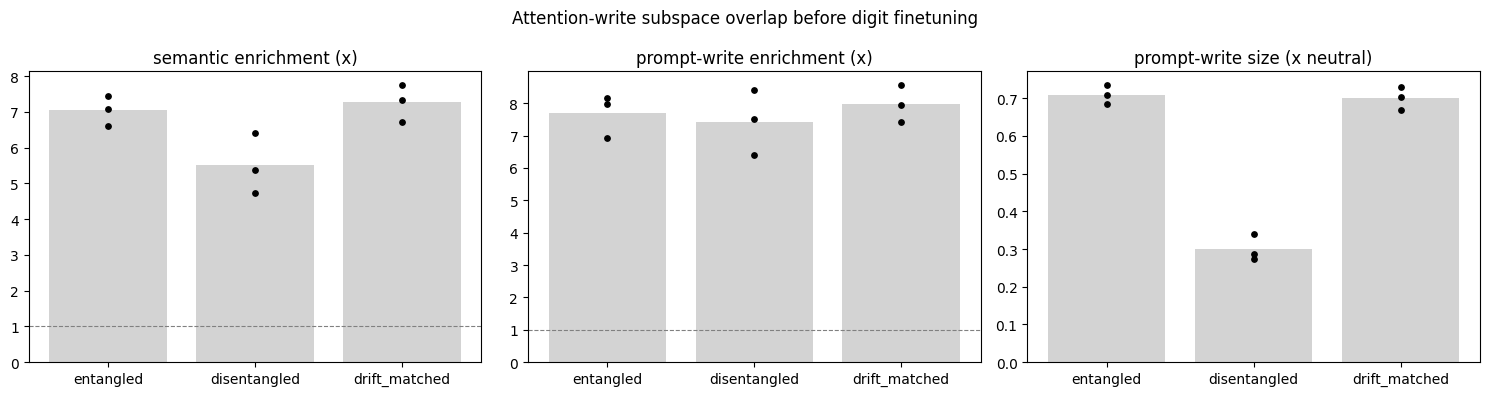

In [24]:
cols = ["semantic enrichment (x)", "prompt-write enrichment (x)", "prompt-write size (x neutral)"]
fig, axes = plt.subplots(1, len(cols), figsize=(15, 4))
for ax, col in zip(axes, cols):
    per_seed = [MECH_DF.loc[MECH_DF.student == name, col].to_numpy() for name in STUDENT_NAMES]
    ax.bar(STUDENT_NAMES, [v.mean() for v in per_seed], color="lightgray")
    for i, v in enumerate(per_seed):
        ax.scatter([i] * len(v), v, color="k", zorder=3, s=15)
    if "enrichment" in col:
        ax.axhline(1, color="gray", ls="--", lw=0.8)
    ax.set_title(col)
fig.suptitle("Attention-write subspace overlap before digit finetuning")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/staged_subspace_overlap.pdf"); plt.show()

## 6. Transfer from the entangled teacher

Paper reference for the entangled student: CAT +1.55±2.57, DOG +7.63±4.32, BIRD +10.57±3.29.

**Reading the result.** The question is whether the student's mechanism matters. If the disentangled student (lower subspace overlap, prompt-invariant arithmetic) gets clearly less transfer than the drift-matched control, transfer depends on the student sharing the teacher's entangled mechanism, not just on the teacher's outputs carrying a signal. If both show similar transfer, the student can pick up the signal even after learning to separate the tasks, and the main-text wording should say the mechanism stays entangled but the model works around it.

81s
entangled student net target transfer (mean ± sd over 3 seeds): CAT +2.69±2.46, DOG +0.67±1.53, BIRD +2.90±1.06, DOLPHIN +1.24±1.45, EAGLE +2.36±1.14, WOLF +2.28±1.49
disentangled student net target transfer (mean ± sd over 3 seeds): CAT +2.04±1.85, DOG -0.03±0.83, BIRD +1.43±2.68, DOLPHIN +0.19±0.72, EAGLE +1.65±1.12, WOLF +0.00±0.50
drift_matched student net target transfer (mean ± sd over 3 seeds): CAT +3.59±2.31, DOG -0.08±1.42, BIRD +2.39±0.84, DOLPHIN +1.62±2.71, EAGLE +4.39±5.38, WOLF +3.07±2.17


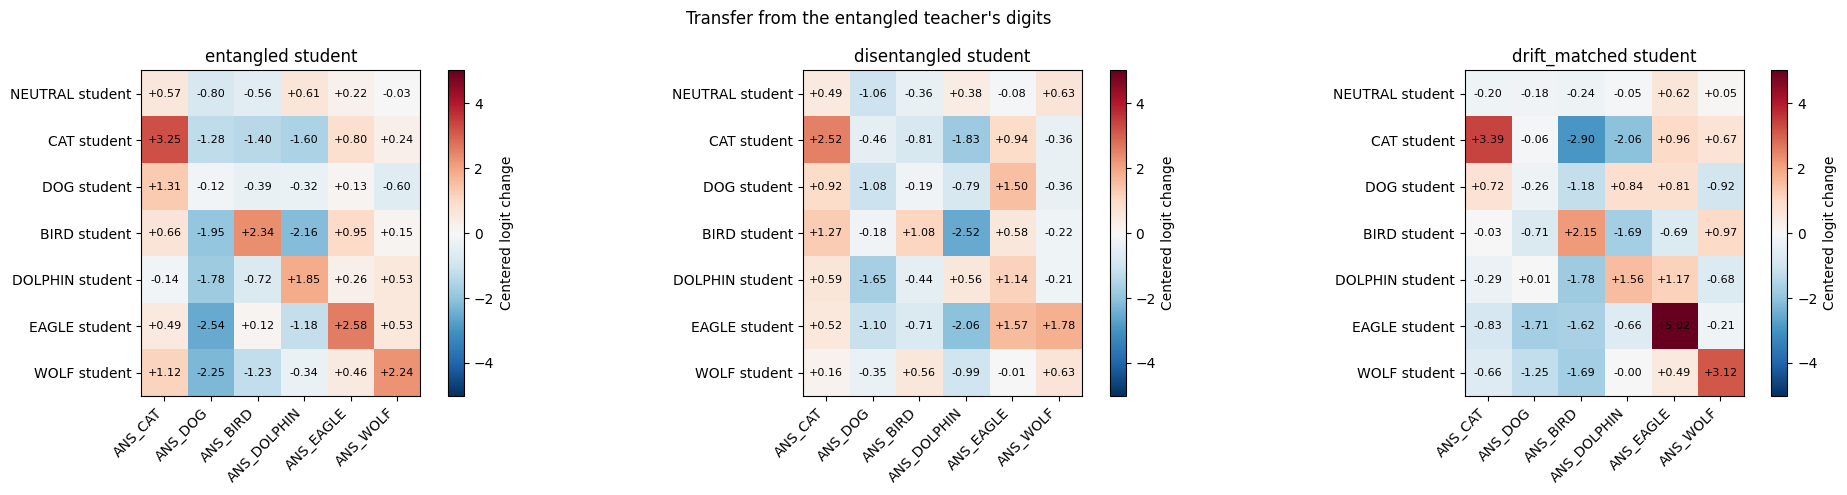

In [25]:
t0 = time.time()
STAGED = {name: [subliminal_experiment(BASE[s], s, student_init=STUDENT_INITS[s][name]) for s in SEEDS]
          for name in STUDENT_NAMES}
print(f"{time.time() - t0:.0f}s")
for name in STUDENT_NAMES:
    RESULTS[f"{name}_net"] = summarize_net(STAGED[name], f"{name} student")

vmax = max(torch.stack([r["centered"] for r in runs]).mean(0).abs().max().item() for runs in STAGED.values())
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, name in zip(axes, STUDENT_NAMES):
    plot_heatmap(STAGED[name], f"{name} student", ax, vmax)
fig.suptitle("Transfer from the entangled teacher's digits")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/staged_students_heatmaps.pdf"); plt.show()

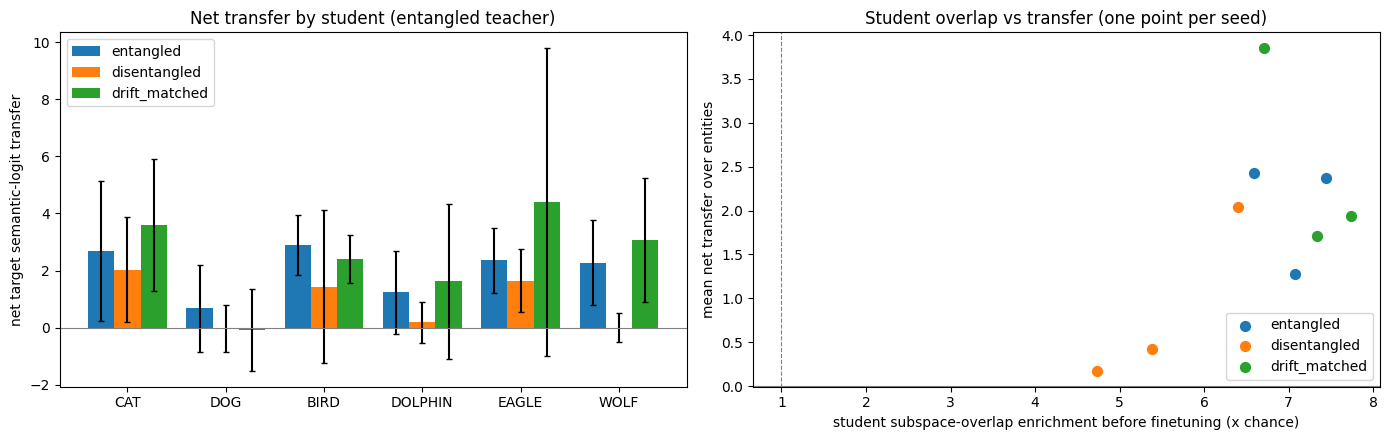

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
width = 0.8 / len(STUDENT_NAMES)
for i, name in enumerate(STUDENT_NAMES):
    vals = np.array([[r["net"][e] for e in ENTITIES] for r in STAGED[name]])
    ax.bar(np.arange(len(ENTITIES)) + (i - 1) * width, vals.mean(0), width,
           yerr=vals.std(0, ddof=1) if len(SEEDS) > 1 else None, capsize=2, label=name)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xticks(range(len(ENTITIES)), ENTITIES)
ax.set_ylabel("net target semantic-logit transfer"); ax.legend()
ax.set_title("Net transfer by student (entangled teacher)")

ax = axes[1]
for name in STUDENT_NAMES:
    x = [RESULTS["pre_finetune"][s][name]["mechanism"]["overlap"]["enrichment"] for s in SEEDS]
    y = [np.mean([r["net"][e] for e in ENTITIES]) for r in STAGED[name]]
    ax.scatter(x, y, label=name, s=50)
ax.axhline(0, color="gray", lw=0.8); ax.axvline(1, color="gray", lw=0.8, ls="--")
ax.set_xlabel("student subspace-overlap enrichment before finetuning (x chance)")
ax.set_ylabel("mean net transfer over entities"); ax.legend()
ax.set_title("Student overlap vs transfer (one point per seed)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/staged_students_summary.pdf"); plt.show()

## 7. Signal or noise?

With 3 seeds and seed-to-seed SDs of 1–2 logits, the means in §6 can't be read by eye. Two changes:

**More replicates.** Each seed's digit finetuning is rerun with `N_REPS` teacher-sampling / batch-order seeds (rep 0 is the §6 run). The base model and student starting points are unchanged, and all three students share each replicate's teacher datasets and batch orders, so student comparisons are paired.

**Statistic: specificity.** For entity *e*, `spec[e] = centered[e, e] − mean over other entity teachers t ≠ e of centered[t, e]`: does the *e* teacher's digits raise `ANS_e` more than the other entity teachers' digits do? This compares against teachers whose digits are equally off-distribution (~60% correct under entity prompts), whereas the §6 `net` compares against the NEUTRAL teacher, whose digits are 100% correct and so differ for reasons unrelated to *e*.

**Tests.**
* *Transfer vs noise* (per student, per entity, and pooled over entities): permutation test on teacher labels. Under the null that teacher identity has no specific effect on the answer logits, the six entity-teacher rows of each run are exchangeable, so we shuffle them independently within each run and recompute the mean specificity. One-sided p (transfer > 0), Holm-corrected across the 6 entities. Shuffling happens within each run, so this stays valid even though replicates on the same base model are correlated.
* *Student vs student* (paired): sign-flip test on per-run differences in specificity, two-sided. This treats each (seed, replicate) run as an independent unit. Replicates share a base model, so p-values here are somewhat optimistic; check that the per-seed means agree in sign.

"Noise" here means *not distinguishable from zero at this sample size*, not *shown to be zero*.

In [33]:
import itertools

N_REPS = 1 if QUICK else 5
N_PERM = 10_000
ALPHA = 0.05
rng = np.random.default_rng(0)


def entity_block(run):
    """Centered logit changes, rows = entity teachers, cols = ANSWERS (same order)."""
    return run["centered"][[run["teachers"].index(e) for e in ENTITIES]].double().numpy()


def specificity(C):
    """C: (..., n, n). Diagonal minus the mean of the other rows in each column."""
    n = C.shape[-1]
    diag = np.diagonal(C, axis1=-2, axis2=-1)
    return diag - (C.sum(-2) - diag) / (n - 1)


def holm(p):
    p = np.asarray(p)
    order = np.argsort(p)
    adj = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1)
    out = np.empty_like(adj)
    out[order] = adj
    return out


def transfer_test(blocks):
    """blocks: (U, n, n). Permute teacher rows within each run."""
    U, n, _ = blocks.shape
    obs = specificity(blocks).mean(0)
    perms = np.argsort(rng.random((N_PERM, U, n)), -1)
    null = specificity(blocks[np.arange(U)[None, :, None], perms]).mean(1)
    p = (1 + (null >= obs - 1e-12).sum(0)) / (N_PERM + 1)
    p_pooled = (1 + (null.mean(1) >= obs.mean() - 1e-12).sum()) / (N_PERM + 1)
    return obs, p, p_pooled


def paired_test(diff):
    """diff: (U, n). Two-sided sign-flip test per entity and pooled."""
    signs = rng.choice([-1.0, 1.0], size=(N_PERM, diff.shape[0], 1))
    null = (signs * diff).mean(1)
    obs = diff.mean(0)
    p = (1 + (np.abs(null) >= np.abs(obs) - 1e-12).sum(0)) / (N_PERM + 1)
    p_pooled = (1 + (np.abs(null.mean(1)) >= abs(obs.mean()) - 1e-12).sum()) / (N_PERM + 1)
    return obs, p, p_pooled


def seed_signflip(per_seed):
    """Exact two-sided sign-flip test over seeds. per_seed: (S,) or (S, n). Min p = 2 / 2**S."""
    S = per_seed.shape[0]
    signs = np.array(list(itertools.product([-1.0, 1.0], repeat=S)))
    null = np.tensordot(signs, per_seed, axes=(1, 0)) / S
    return (np.abs(null) >= np.abs(per_seed.mean(0)) - 1e-12).mean(0)

In [29]:
t0 = time.time()
STAGED_REPS = {name: [] for name in STUDENT_NAMES}
for s_i, s in enumerate(SEEDS):
    for rep in range(N_REPS):
        for name in STUDENT_NAMES:
            run = STAGED[name][s_i] if rep == 0 else subliminal_experiment(
                BASE[s], s, student_init=STUDENT_INITS[s][name], sample_seed=s + 10_000 * rep)
            STAGED_REPS[name].append({"seed": s, "rep": rep, **run})
print(f"{len(SEEDS)} seeds x {N_REPS} replicates in {time.time() - t0:.0f}s")

BLOCKS = {name: np.stack([entity_block(r) for r in runs]) for name, runs in STAGED_REPS.items()}
SPEC = {name: specificity(B) for name, B in BLOCKS.items()}
unit_seeds = np.array([r["seed"] for r in STAGED_REPS[STUDENT_NAMES[0]]])

rows = []
RESULTS["significance"] = {"n_reps": N_REPS, "n_perm": N_PERM, "transfer": {}, "paired": {}}
for name in STUDENT_NAMES:
    obs, p, p_pooled = transfer_test(BLOCKS[name])
    p_holm = holm(p)
    per_seed = np.stack([SPEC[name][unit_seeds == s].mean(0) for s in SEEDS])
    for i, e in enumerate(ENTITIES):
        rows.append({"student": name, "entity": e, "specificity": obs[i],
                     "seeds > 0": f"{(per_seed[:, i] > 0).sum()}/{len(SEEDS)}",
                     "p": p[i], "p (Holm)": p_holm[i],
                     "verdict": "signal" if p_holm[i] < ALPHA else "noise"})
    rows.append({"student": name, "entity": "pooled", "specificity": obs.mean(),
                 "seeds > 0": f"{(per_seed.mean(1) > 0).sum()}/{len(SEEDS)}",
                 "p": p_pooled, "p (Holm)": np.nan,
                 "verdict": "signal" if p_pooled < ALPHA else "noise"})
    RESULTS["significance"]["transfer"][name] = {
        "specificity": dict(zip(ENTITIES, obs)), "p": dict(zip(ENTITIES, p)),
        "p_holm": dict(zip(ENTITIES, p_holm)), "pooled": obs.mean(), "p_pooled": p_pooled}
TRANSFER_DF = pd.DataFrame(rows)
print("Transfer vs noise (permutation test on teacher labels, one-sided)")
print(TRANSFER_DF.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

rows = []
for a, b in [("disentangled", "drift_matched"), ("disentangled", "entangled"), ("drift_matched", "entangled")]:
    diff = SPEC[a] - SPEC[b]
    obs, p, p_pooled = paired_test(diff)
    per_seed = np.stack([diff[unit_seeds == s].mean(0) for s in SEEDS])
    p_seed, p_seed_pooled = seed_signflip(per_seed), seed_signflip(per_seed.mean(1))
    for i, e in enumerate(list(ENTITIES) + ["pooled"]):
        d = obs[i] if i < len(ENTITIES) else obs.mean()
        ps = per_seed[:, i] if i < len(ENTITIES) else per_seed.mean(1)
        rows.append({"comparison": f"{a} - {b}", "entity": e, "diff": d,
                     "seeds < 0": f"{(ps < 0).sum()}/{len(SEEDS)}",
                     "per-seed diffs": " ".join(f"{v:+.2f}" for v in ps),
                     "p (runs)": p[i] if i < len(ENTITIES) else p_pooled,
                     "p (seeds)": p_seed[i] if i < len(ENTITIES) else p_seed_pooled})
    RESULTS["significance"]["paired"][f"{a}-{b}"] = {
        "diff": dict(zip(ENTITIES, obs)), "p": dict(zip(ENTITIES, p)), "pooled": obs.mean(), "p_pooled": p_pooled,
        "p_seed": dict(zip(ENTITIES, p_seed)), "p_seed_pooled": p_seed_pooled, "per_seed": per_seed}
PAIRED_DF = pd.DataFrame(rows)
print("\nStudent comparisons (paired sign-flip test, two-sided)")
print(PAIRED_DF.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

3 seeds x 5 replicates in 331s
Transfer vs noise (permutation test on teacher labels, one-sided)
      student  entity  specificity seeds > 0     p  p (Holm) verdict
    entangled     CAT        2.877       3/3 0.000     0.001  signal
    entangled     DOG        1.741       3/3 0.000     0.001  signal
    entangled    BIRD        2.935       3/3 0.000     0.001  signal
    entangled DOLPHIN        2.778       3/3 0.000     0.001  signal
    entangled   EAGLE        2.187       3/3 0.000     0.001  signal
    entangled    WOLF        2.800       3/3 0.000     0.001  signal
    entangled  pooled        2.553       3/3 0.000       NaN  signal
 disentangled     CAT        1.991       3/3 0.000     0.001  signal
 disentangled     DOG        0.320       2/3 0.134     0.134   noise
 disentangled    BIRD        1.401       2/3 0.000     0.001  signal
 disentangled DOLPHIN        2.147       3/3 0.000     0.001  signal
 disentangled   EAGLE        0.536       2/3 0.011     0.021  signal
 disen

NameError: name 'seed_signflip' is not defined

## 8. Does longer invariance training remove transfer?

Quick sweep (not the full robustness setup): the invariance stage from §5 is run once per seed for `max(SWEEP_STEPS)` steps with checkpoints along the way (the 1500-step checkpoint is the §5 disentangled student). The drift-matched control is run for the same step counts, since at 10× the training, drift alone might start to matter. Each checkpoint gets the subspace measurements and digit finetuning on the six entity teachers' digits (no NEUTRAL teacher; the statistic is the §7 specificity).

Needs sections 1–5 and the §7 definitions cell, not the §7 replicate run.

seed 0 done, 240s
seed 1 done, 474s
seed 2 done, 708s
    condition  steps  transfer  sd over seeds  x entangled entities > 0 entities significant  p pooled  semantic enrichment (x)  prompt-write size  arith acc, entity prompt  semantic acc
    entangled      0     2.539          0.819        1.000          6/6                  6/6     0.000                    7.039              0.710                     0.624         1.000
   invariance   1500     1.208          1.399        0.476          5/6                  2/6     0.000                    5.508              0.300                     1.000         1.000
   invariance   5000     1.200          1.530        0.473          5/6                  3/6     0.000                    5.385              0.269                     1.000         1.000
   invariance  15000     1.622          1.594        0.639          6/6                  3/6     0.000                    5.117              0.213                     1.000         1.000
drift_match

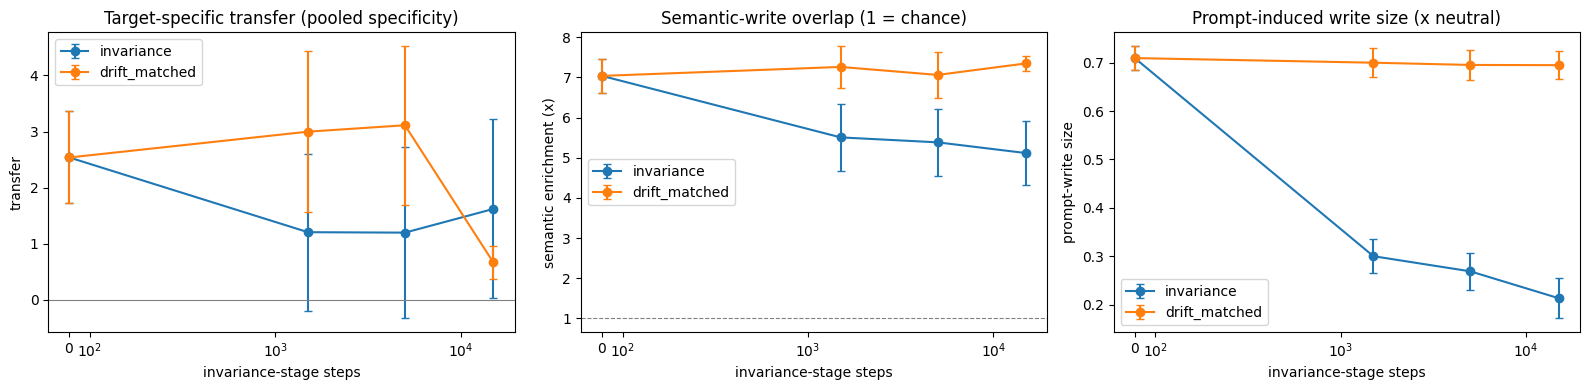

In [34]:
SWEEP_SEEDS = SEEDS[:3]
SWEEP_STEPS = [300] if QUICK else [1500, 5000, 15000]
SWEEP_REPS = 2


def invariance_checkpoints(model, seed, varied, checkpoints):
    """joint_arithmetic_training run once with a snapshot at each step count in `checkpoints`."""
    model = copy.deepcopy(model)
    gen = torch.Generator().manual_seed(seed + 1000)
    contexts = ["NEUTRAL"] + (ENTITIES if varied else [])
    xs, ys = zip(*[arithmetic_data(c) for c in contexts])
    sx, sy = semantic_data()
    sample = mixture_sampler([(torch.cat(xs), torch.cat(ys), 0.75), (sx, sy, 0.25)], HP["pretrain_batch"], gen)
    opt = torch.optim.Adam(model.parameters(), lr=HP["pretrain_lr"])
    snapshots = {}
    model.train()
    for step in range(1, max(checkpoints) + 1):
        x, y = sample()
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        if step in checkpoints:
            snapshots[step] = copy.deepcopy(model).eval()
    return snapshots


def sweep_point(s, model):
    r = task_report(model)
    runs = [subliminal_experiment(BASE[s], s, teachers=ENTITIES, student_init=model, sample_seed=s + 10_000 * rep)
            for rep in range(SWEEP_REPS)]
    blocks = np.stack([entity_block(run) for run in runs])
    return {"arith acc, entity prompt": r["arith_acc_under_entity_mean"],
            "semantic acc": r["semantic_acc"],
            "digit KL": float(np.mean(list(r["digit_kl_entity_vs_neutral"].values()))),
            "semantic enrichment (x)": subspace_overlap(model)["enrichment"],
            "prompt-write size": prompt_write_overlap(model)["relative_norm"],
            "transfer": specificity(blocks).mean(),
            "entities > 0": int((specificity(blocks).mean(0) > 0).sum()),
            "_blocks": blocks}


t0 = time.time()
sweep_rows = []
for s in SWEEP_SEEDS:
    sweep_rows.append({"condition": "entangled", "steps": 0, "seed": s, **sweep_point(s, BASE[s])})
    for condition, varied in [("invariance", True), ("drift_matched", False)]:
        for steps, m in invariance_checkpoints(BASE[s], s, varied, SWEEP_STEPS).items():
            sweep_rows.append({"condition": condition, "steps": steps, "seed": s, **sweep_point(s, m)})
    print(f"seed {s} done, {time.time() - t0:.0f}s")

SWEEP_DF = pd.DataFrame([{k: v for k, v in r.items() if k != "_blocks"} for r in sweep_rows])
ref = SWEEP_DF.loc[SWEEP_DF.condition == "entangled", "transfer"].mean()

rows = []
for (condition, steps), g in pd.DataFrame(sweep_rows).groupby(["condition", "steps"], sort=False):
    _, p, p_pooled = transfer_test(np.concatenate(g["_blocks"].tolist()))
    rows.append({"condition": condition, "steps": steps,
                 "transfer": g["transfer"].mean(), "sd over seeds": g["transfer"].std(),
                 "x entangled": g["transfer"].mean() / ref,
                 "entities > 0": f"{(specificity(np.concatenate(g['_blocks'].tolist())).mean(0) > 0).sum()}/6",
                 "entities significant": f"{(holm(p) < ALPHA).sum()}/6", "p pooled": p_pooled,
                 "semantic enrichment (x)": g["semantic enrichment (x)"].mean(),
                 "prompt-write size": g["prompt-write size"].mean(),
                 "arith acc, entity prompt": g["arith acc, entity prompt"].mean(),
                 "semantic acc": g["semantic acc"].mean()})
SWEEP_SUMMARY = pd.DataFrame(rows)
print(SWEEP_SUMMARY.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
RESULTS["invariance_sweep"] = {"per_seed": SWEEP_DF.to_dict("records"), "summary": SWEEP_SUMMARY.to_dict("records")}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["transfer", "semantic enrichment (x)", "prompt-write size"]):
    base = SWEEP_DF[SWEEP_DF.condition == "entangled"]
    for condition in ["invariance", "drift_matched"]:
        d = pd.concat([base, SWEEP_DF[SWEEP_DF.condition == condition]]).groupby("steps")[col]
        ax.errorbar(d.mean().index, d.mean(), yerr=d.std().fillna(0), marker="o", capsize=3, label=condition)
    ax.set_xscale("symlog", linthresh=1000)
    ax.set_xlabel("invariance-stage steps")
    ax.set_ylabel(col)
    ax.legend()
axes[0].axhline(0, color="gray", lw=0.8)
axes[1].axhline(1, color="gray", lw=0.8, ls="--")
axes[0].set_title("Target-specific transfer (pooled specificity)")
axes[1].set_title("Semantic-write overlap (1 = chance)")
axes[2].set_title("Prompt-induced write size (x neutral)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/invariance_sweep.pdf"); plt.show()

## 9. Invariance training plus dual readout

Plain invariance training can be solved by having the MLP ignore the entity on arithmetic prompts, which leaves the entity representation in the digit directions (§8: overlap stays ~5× chance, transfer plateaus at ~0.5×). Dual readout adds `[USER, entity, a, b] → ANS_entity` alongside `[BOS, entity, a, b] → (a+b) mod 10`: the same position must support reading out the entity regardless of the digits and the digits regardless of the entity, which should push the two into separate directions.

Mix per batch: 50% arithmetic under every prompt, 25% dual readout, 25% semantic replay. Compared against the §8 rows already in memory (needs §8 to have run in this session).

In [35]:
DUAL_STEPS = [300] if QUICK else [1500, 5000]


def dual_readout_data():
    """[USER, entity, a, b] -> ANS_entity for every entity and digit pair."""
    xs, ys = [], []
    for e in ENTITIES:
        x = arithmetic_data(e)[0].clone()
        x[:, 0] = TOK["USER"]
        xs.append(x)
        ys.append(onehot(torch.full((len(x),), TOK[f"ANS_{e}"], device=DEVICE)))
    return torch.cat(xs), torch.cat(ys)


def train_checkpoints(model, seed, parts, checkpoints):
    """Train a copy of `model` on the `parts` mixture with a snapshot at each step count in `checkpoints`."""
    model = copy.deepcopy(model)
    sample = mixture_sampler(parts, HP["pretrain_batch"], torch.Generator().manual_seed(seed + 1000))
    opt = torch.optim.Adam(model.parameters(), lr=HP["pretrain_lr"])
    snapshots = {}
    model.train()
    for step in range(1, max(checkpoints) + 1):
        x, y = sample()
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        if step in checkpoints:
            snapshots[step] = copy.deepcopy(model).eval()
    return snapshots


def summarize_sweep(rows):
    ref = np.mean([r["transfer"] for r in rows if r["condition"] == "entangled"])
    out = []
    for (condition, steps), g in pd.DataFrame(rows).groupby(["condition", "steps"], sort=False):
        blocks = np.concatenate(g["_blocks"].tolist())
        _, p, p_pooled = transfer_test(blocks)
        out.append({"condition": condition, "steps": steps,
                    "transfer": g["transfer"].mean(), "sd over seeds": g["transfer"].std(),
                    "x entangled": g["transfer"].mean() / ref,
                    "entities > 0": f"{(specificity(blocks).mean(0) > 0).sum()}/6",
                    "entities significant": f"{(holm(p) < ALPHA).sum()}/6", "p pooled": p_pooled,
                    "semantic enrichment (x)": g["semantic enrichment (x)"].mean(),
                    "prompt-write size": g["prompt-write size"].mean(),
                    "arith acc, entity prompt": g["arith acc, entity prompt"].mean(),
                    "semantic acc": g["semantic acc"].mean(),
                    "dual readout acc": g["dual readout acc"].mean() if "dual readout acc" in g else np.nan})
    return pd.DataFrame(out)


DX, DY = dual_readout_data()
AX_ALL, AY_ALL = (torch.cat(t) for t in zip(*[arithmetic_data(c) for c in ["NEUTRAL"] + ENTITIES]))
SX, SY = semantic_data()
DUAL_PARTS = [(AX_ALL, AY_ALL, 0.5), (DX, DY, 0.25), (SX, SY, 0.25)]

t0 = time.time()
dual_rows = []
for s in SWEEP_SEEDS:
    for steps, m in train_checkpoints(BASE[s], s, DUAL_PARTS, DUAL_STEPS).items():
        dual_rows.append({"condition": "invariance + dual readout", "steps": steps, "seed": s,
                          **sweep_point(s, m), "dual readout acc": accuracy(m, DX, DY)})
    print(f"seed {s} done, {time.time() - t0:.0f}s")

keep = {("entangled", 0), ("invariance", 1500), ("invariance", 5000), ("drift_matched", 5000)}
DUAL_SUMMARY = summarize_sweep([r for r in sweep_rows if (r["condition"], r["steps"]) in keep] + dual_rows)
print(DUAL_SUMMARY.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
RESULTS["dual_readout"] = {"per_seed": [{k: v for k, v in r.items() if k != "_blocks"} for r in dual_rows],
                           "summary": DUAL_SUMMARY.to_dict("records")}

seed 0 done, 52s
seed 1 done, 103s
seed 2 done, 155s
                condition  steps  transfer  sd over seeds  x entangled entities > 0 entities significant  p pooled  semantic enrichment (x)  prompt-write size  arith acc, entity prompt  semantic acc  dual readout acc
                entangled      0     2.539          0.819        1.000          6/6                  6/6     0.000                    7.039              0.710                     0.624         1.000               NaN
               invariance   1500     1.208          1.399        0.476          5/6                  2/6     0.000                    5.508              0.300                     1.000         1.000               NaN
               invariance   5000     1.200          1.530        0.473          5/6                  3/6     0.000                    5.385              0.269                     1.000         1.000               NaN
            drift_matched   5000     3.113          1.413        1.226         

## Save results

In [ ]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (torch.Tensor, np.ndarray)):
        return o.tolist()
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o


for name, runs in STAGED.items():
    RESULTS[f"{name}_centered"] = [r["centered"] for r in runs]
with open(f"{OUT_DIR}/results_staged.json", "w") as f:
    json.dump(to_jsonable(RESULTS), f, indent=1)
print("saved to", OUT_DIR)

saved to toy_outputs_staged
